In [1]:
# src/tsc_model.py
from pathlib import Path
import joblib
import numpy as np
from pprint import pprint
from sklearn.pipeline import Pipeline
import sktime
from src.load_dataset import load_ecg200_data

In [2]:
model_path="models/ECG200/miniRocket_norm.pkl"
model = joblib.load(model_path)

c:\Users\chriz\miniconda3\envs\INF265\Lib\site-packages\sklearn\base.py:376: InconsistentVersionWarning: Trying to unpickle estimator RidgeClassifierCV from version 1.6.1 when using version 1.5.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\chriz\miniconda3\envs\INF265\Lib\site-packages\sklearn\base.py:376: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.5.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\chriz\miniconda3\envs\INF265\Lib\site-packages\sklearn\base.py:376: InconsistentVersionWarning: Trying to unpickle estimator LabelBinarizer from version 1.6.1 when using 

In [3]:
print("type:", type(model))
print("module:", type(model).__module__)
print("is sklearn Pipeline:", isinstance(model, Pipeline))

# 1) High-level constructor params
print("\n=== get_params (shallow) ===")
pprint(model.get_params(deep=False))

# 2) Fitted/internal attributes that may hold wrapped estimators/pipelines
print("\n=== internal fitted attrs ending with '_' ===")
for name in sorted([n for n in dir(model) if n.endswith("_") and not n.startswith("__")]):
    try:
        val = getattr(model, name)
        print(f"{name}: {type(val)}")
    except Exception as e:
        print(f"{name}: <unavailable: {e}>")

# 3) If it directly exposes sklearn-style steps
if hasattr(model, "steps"):
    print("\n=== model.steps ===")
    for step_name, step_obj in model.steps:
        print(f"- {step_name}: {type(step_obj)}")

# 4) Common sktime wrappers: inspect likely nested estimator attrs
for candidate in ["estimator", "estimator_", "classifier", "classifier_", "pipeline", "pipeline_"]:
    if hasattr(model, candidate):
        obj = getattr(model, candidate)
        print(f"\n=== {candidate} ===")
        print(type(obj))
        if hasattr(obj, "steps"):
            print("steps:")
            for step_name, step_obj in obj.steps:
                print(f"- {step_name}: {type(step_obj)}")

type: <class 'sktime.classification.kernel_based._rocket_classifier.RocketClassifier'>
module: sktime.classification.kernel_based._rocket_classifier
is sklearn Pipeline: False

=== get_params (shallow) ===
{'max_dilations_per_kernel': 32,
 'n_features_per_kernel': 4,
 'n_jobs': 1,
 'num_kernels': 10000,
 'random_state': None,
 'rocket_transform': 'rocket',
 'use_multivariate': 'no'}

=== internal fitted attrs ending with '_' ===
_repr_html_: <class 'method'>
_repr_mimebundle_: <class 'method'>
classes_: <class 'numpy.ndarray'>
estimator_: <class 'sktime.classification.compose._pipeline.SklearnClassifierPipeline'>
fit_time_: <class 'int'>
multivar_rocket_: <class 'sktime.classification.compose._pipeline.SklearnClassifierPipeline'>
n_classes_: <class 'int'>
num_kernels_: <class 'int'>
univar_rocket_: <class 'sktime.classification.compose._pipeline.SklearnClassifierPipeline'>

=== estimator_ ===
<class 'sktime.classification.compose._pipeline.SklearnClassifierPipeline'>


In [4]:
from pprint import pprint

pipe = model.estimator_
print("inner pipeline type:", type(pipe))
print("inner pipeline module:", type(pipe).__module__)

# show pipeline-like/public attrs
print("\npublic attrs:")
print([a for a in dir(pipe) if not a.startswith("_")][:80])

# print parameters (deep=False = compact)
print("\ninner params (shallow):")
pprint(pipe.get_params(deep=False))

# try common step containers used by sklearn/sktime wrappers
for attr in ["steps", "named_steps", "transformers", "classifier", "classifier_",
             "estimator", "estimator_", "transformer", "transformer_"]:
    if hasattr(pipe, attr):
        val = getattr(pipe, attr)
        print(f"\n{attr}: {type(val)}")
        if attr == "steps" and isinstance(val, list):
            for name, step in val:
                print(f" - {name}: {type(step)}")

inner pipeline type: <class 'sktime.classification.compose._pipeline.SklearnClassifierPipeline'>
inner pipeline module: sktime.classification.compose._pipeline

public attrs:
['EST_TYPE', 'EST_TYPE_PLURAL', 'FLIPPED_TAGS', 'GET_FITTED_PARAMS_NESTING', 'METADATA_REQ_IN_CHECKS', 'TASK', 'VECTORIZATION_ATTR', 'alias_dict', 'check_is_fitted', 'classes_', 'classifier', 'classifier_', 'clone', 'clone_tags', 'create_test_instance', 'create_test_instances_and_names', 'deprecate_dict', 'fit', 'fit_predict', 'fit_predict_proba', 'fit_time_', 'get_class_tag', 'get_class_tags', 'get_config', 'get_fitted_params', 'get_param_defaults', 'get_param_names', 'get_params', 'get_tag', 'get_tags', 'get_test_params', 'is_composite', 'is_fitted', 'load_from_path', 'load_from_serial', 'n_classes_', 'predict', 'predict_proba', 'reset', 'save', 'score', 'set_config', 'set_params', 'set_random_state', 'set_tags', 'steps_', 'transformers', 'transformers_']

inner params (shallow):
{'classifier': RidgeClassifierCV

c:\Users\chriz\miniconda3\envs\INF265\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


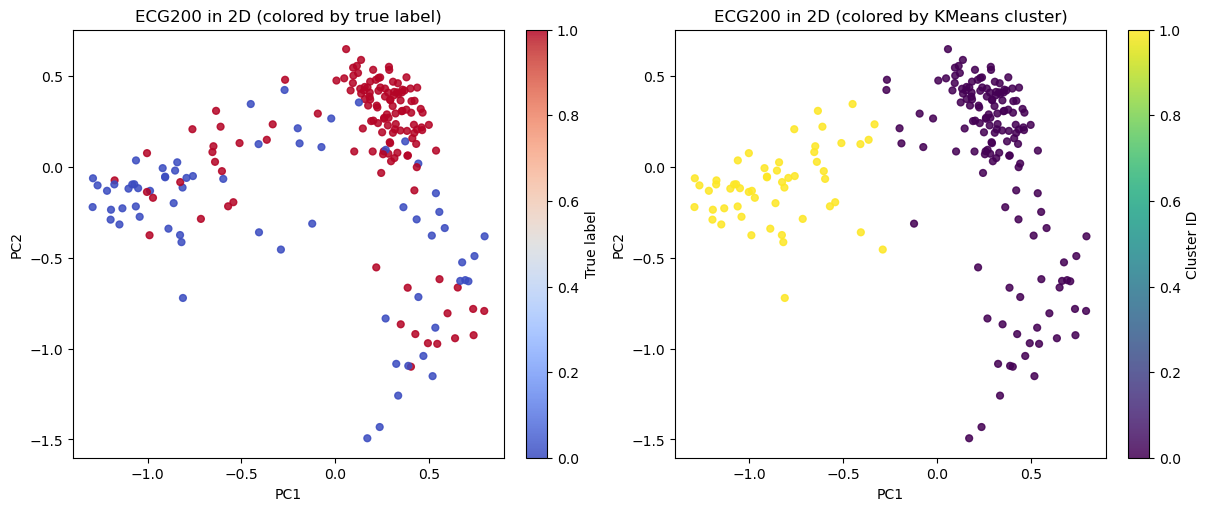

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from src.load_dataset import load_ecg200_data

# Load splits
data = load_ecg200_data("data/ECG200")

# Combine all splits for one global cluster view
X = np.vstack([
    data["train"]["samples"],
    data["validation"]["samples"],
    data["test"]["samples"],
])
y = np.hstack([
    data["train"]["labels"],
    data["validation"]["labels"],
    data["test"]["labels"],
])

# 2D projection for visualization
X_2d = PCA(n_components=2, random_state=42).fit_transform(X)

# Unsupervised clustering (2 clusters for ECG200 binary classes)
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X)

# Plot: true labels vs discovered clusters
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

s1 = axes[0].scatter(X_2d[:, 0], X_2d[:, 1], c=y, cmap="coolwarm", s=24, alpha=0.85)
axes[0].set_title("ECG200 in 2D (colored by true label)")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
fig.colorbar(s1, ax=axes[0], label="True label")

s2 = axes[1].scatter(X_2d[:, 0], X_2d[:, 1], c=clusters, cmap="viridis", s=24, alpha=0.85)
axes[1].set_title("ECG200 in 2D (colored by KMeans cluster)")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
fig.colorbar(s2, ax=axes[1], label="Cluster ID")

plt.show()